## 1. Importer les outils

In [1]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

## Import Scaled File


In [70]:
data_path = "../data/processed/scaled_features.csv"

cleaned_path = "../data/processed/cleaned_data.csv"

df_clean = pd.read_csv(cleaned_path)
df = pd.read_csv(data_path)

features = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

X_scaled = df[features]

X_scaled.head()



,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.865208,-0.033213,0.628942,1.045430,0.169821,0.468492,1.425995
1,-1.202553,-0.525640,0.000300,-1.072830,-0.846881,-0.365061,-0.190672
2,2.013964,-0.689782,-0.481658,0.772437,-1.326183,0.604397,-0.105584
3,-1.071266,-0.525640,-0.628341,-0.606895,-0.629016,-0.920763,-1.041549
4,0.504171,-2.659489,0.628942,0.152559,1.549630,5.484909,-0.020496


## 2. Tester plusieurs valeurs de K

In [71]:
inertias = []
silhouette_scores = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    # Inertie
    inertias.append(kmeans.inertia_)

    # Silhouette
    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

In [72]:
results_k = pd.DataFrame({
    "K": list(K_range),
    "Inertia": inertias,
    "Silhouette": silhouette_scores
})

print(results_k)

    K      Inertia  Silhouette
0   2  4142.864109    0.227771
1   3  3655.934931    0.206063
2   4  3286.127816    0.161658
3   5  3057.239517    0.166730
4   6  2846.642166    0.171005
5   7  2658.443252    0.172327
6   8  2540.169861    0.158753
7   9  2412.663934    0.172263
8  10  2307.832881    0.157814


## 4. Méthode du coude — Elbow

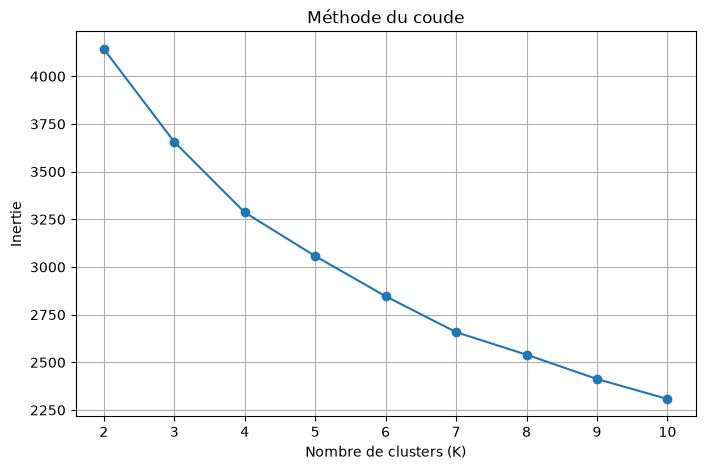

In [73]:
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    inertias,
    marker="o"
)

plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.title("Méthode du coude")

plt.xticks(list(K_range))
plt.grid(True)

plt.show()

## 5. Silhouette Score

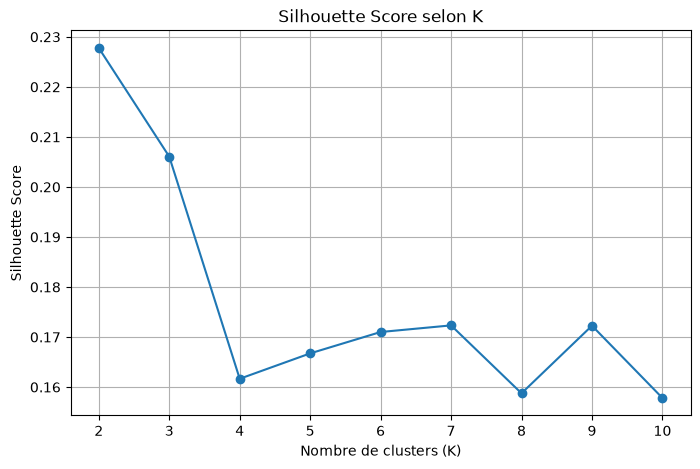

In [74]:
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score selon K")

plt.xticks(list(K_range))
plt.grid(True)

plt.show()

## best_k_silhouette

In [75]:
best_k_silhouette = K_range[
    silhouette_scores.index(
        max(silhouette_scores)
    )
]

print(
    "Meilleur K selon Silhouette :",
    best_k_silhouette
)

k_final = 2

Meilleur K selon Silhouette : 2


La valeur optimale de K a été déterminée en combinant la méthode du coude et le coefficient de silhouette. La méthode du coude permet d'identifier la zone où l'amélioration de l'inertie devient marginale, tandis que le score de silhouette mesure la qualité de séparation des clusters. Le choix final de K est effectué en considérant conjointement ces deux critères et l'interprétabilité des groupes obtenus.

## 9. Entraîner K-Means final

In [76]:
kmeans_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

clusters = kmeans_final.fit_predict(
    X_scaled
)

## 10. Ajouter Cluster au dataset

In [77]:
df_clean["Cluster"] = clusters

In [78]:
df_clean.head()

,Unnamed: 0,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Cluster
0,0,6,148.0,72.0,35.0,255.0,33.6,0.627,50.0,0
1,1,1,85.0,66.0,29.0,48.6,26.6,0.351,31.0,1
2,2,8,183.0,64.0,24.4,228.4,23.3,0.672,32.0,0
3,3,1,89.0,66.0,23.0,94.0,28.1,0.167,21.0,1
4,4,0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,0


## Count each Patient in cluster 

In [79]:
cluster_counts = df_clean["Cluster"].value_counts().sort_index()

print(cluster_counts)

Cluster
0    324
1    444
Name: count, dtype: int64


## 12. Visualiser la répartition des clusters

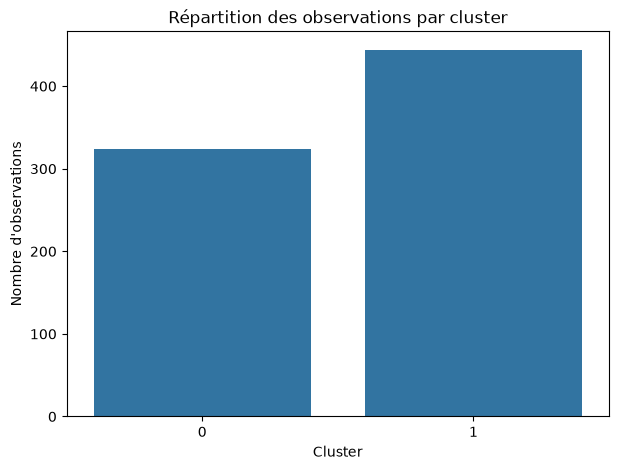

In [80]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Cluster"
)

plt.title("Répartition des observations par cluster")
plt.xlabel("Cluster")
plt.ylabel("Nombre d'observations")

plt.show()

## 13. Analyse des caractéristiques de chaque Cluster

In [81]:
cluster_means = df_clean.groupby(
    "Cluster"
)[features].mean()

print(cluster_means)

            Glucose  BloodPressure  SkinThickness     Insulin        BMI  \
Cluster                                                                    
0        141.695679      79.148148      34.643210  211.899383  36.528148   
1        107.003153      67.483784      24.877027  110.252703  29.440811   

         DiabetesPedigreeFunction        Age  
Cluster                                       
0                        0.537049  40.234568  
1                        0.424318  28.137387  


## 14. Visualiser les moyennes des clusters

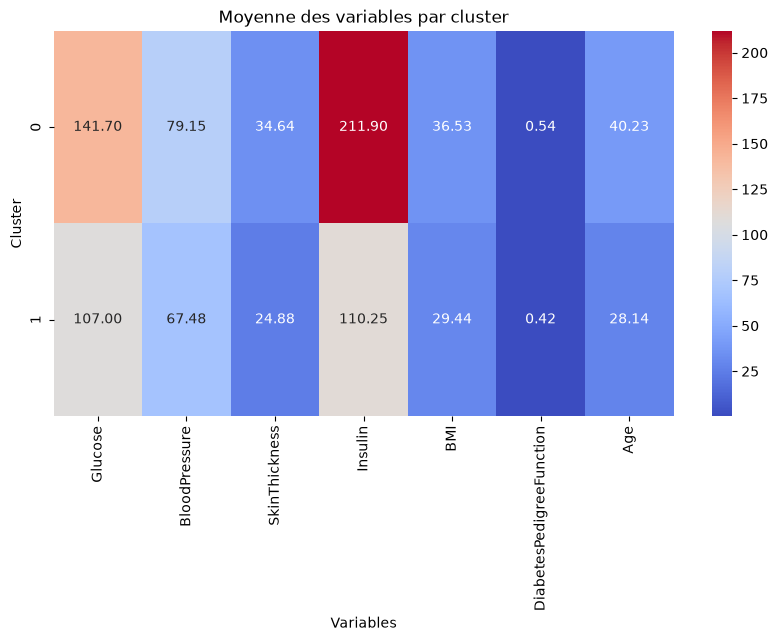

In [82]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    cluster_means,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Moyenne des variables par cluster")
plt.xlabel("Variables")
plt.ylabel("Cluster")

plt.show()

## 16. Scatter plot : Glucose × Age

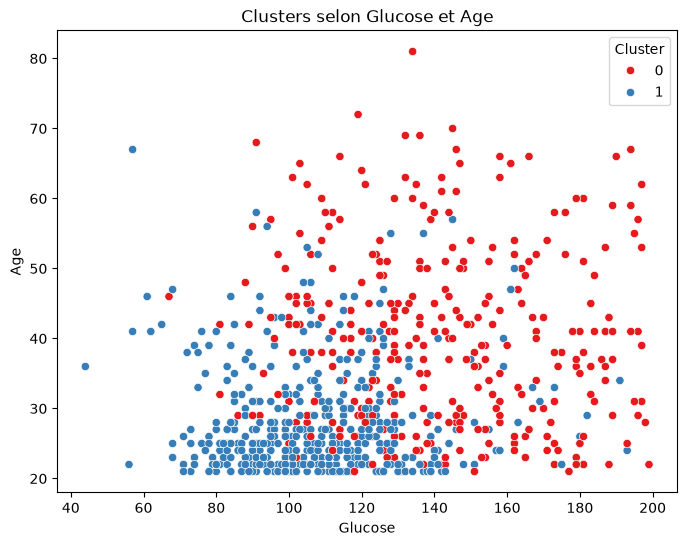

In [83]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_clean,
    x="Glucose",
    y="Age",
    hue="Cluster",
    palette="Set1"
)

plt.title("Clusters selon Glucose et Age")
plt.show()

## Repartition du cluster 

In [84]:
for cluster in sorted(df_clean["Cluster"].unique()):

    data_cluster = df_clean[
        df_clean["Cluster"] == cluster
    ]

    glucose_high = (
        data_cluster["Glucose"] > 126
    ).mean() * 100

    bmi_high = (
        data_cluster["BMI"] > 30
    ).mean() * 100

    dpf_high = (
        data_cluster["DiabetesPedigreeFunction"] > 0.5
    ).mean() * 100

    print(f"\nCluster {cluster}")
    print(f"Glucose > 126 : {glucose_high:.2f}%")
    print(f"BMI > 30 : {bmi_high:.2f}%")
    print(f"DPF > 0.5 : {dpf_high:.2f}%")


Cluster 0
Glucose > 126 : 67.90%
BMI > 30 : 85.19%
DPF > 0.5 : 44.75%

Cluster 1
Glucose > 126 : 15.77%
BMI > 30 : 43.47%
DPF > 0.5 : 29.73%


## Visualization du clusters

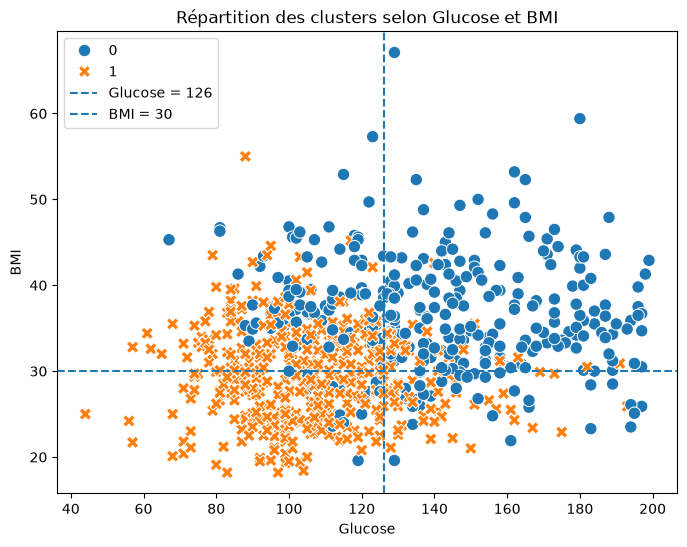

In [85]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_clean,
    x="Glucose",
    y="BMI",
    hue="Cluster",
    style="Cluster",
    s=80
)

plt.axvline(
    126,
    linestyle="--",
    label="Glucose = 126"
)

plt.axhline(
    30,
    linestyle="--",
    label="BMI = 30"
)

plt.title("Répartition des clusters selon Glucose et BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.legend()

plt.show()

# Heat MAP du cluster

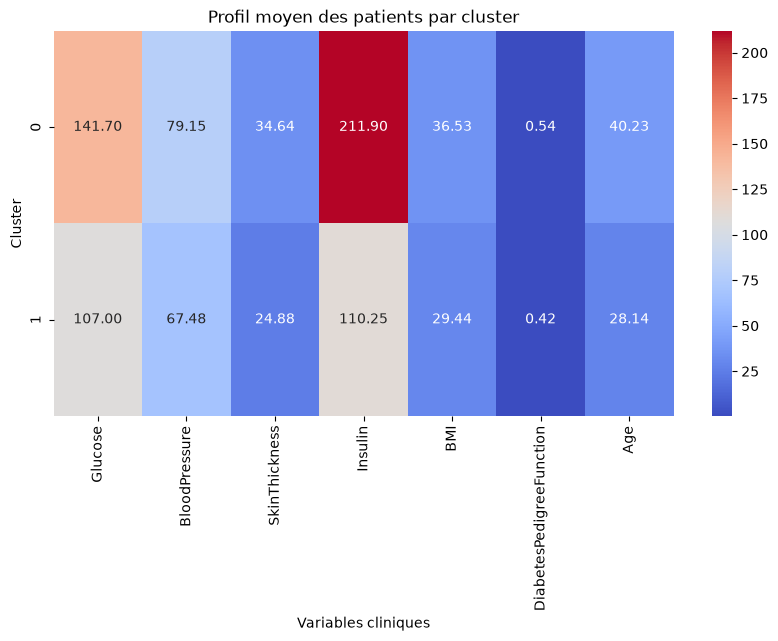

In [86]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    cluster_means,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title(
    "Profil moyen des patients par cluster"
)

plt.xlabel("Variables cliniques")
plt.ylabel("Cluster")

plt.show()

L’application de l’algorithme K-Means avec K=2 a permis de répartir les 768 observations en deux groupes : le Cluster 0 contient 335 patients, tandis que le Cluster 1 contient 433 patients.

L’analyse des moyennes montre des différences importantes entre les deux groupes. Le Cluster 0 présente des valeurs moyennes plus élevées pour le Glucose (141,45), l’IMC (36,21) et la Diabetes Pedigree Function (0,530), tandis que le Cluster 1 présente respectivement des moyennes de 106,34, 29,55 et 0,427.

Selon les seuils définis dans le projet (Glucose > 126, BMI > 30 et Diabetes Pedigree Function > 0,5), les moyennes du Cluster 0 dépassent les trois seuils. Ce cluster est donc interprété comme un profil présentant des caractéristiques associées à un risque élevé de diabète selon les critères retenus. Le Cluster 1 présente, quant à lui, des valeurs moyennes inférieures à ces seuils et correspond à un profil comparativement moins élevé selon cette règle.

Cette interprétation constitue une catégorisation analytique issue du clustering et des seuils définis dans le projet ; elle ne constitue pas un diagnostic médical individuel.


## Add Risk_category Field

In [87]:
df_clean["risk_category"] = df_clean["Cluster"].map({
    0: "High Risk",
    1: "Low Risk"
})

## Save Cluster and new field to dataset

In [88]:
df_clean.to_csv(
    "../data/processed/clustering_data.csv",
    index=False
)